In [ ]:
# pm/V scaling (added): saved loop amplitude = lock-in output x 1e-3 x 15.95 (AmpInvOLS, nm/V).
# With a 10 V full-scale lock-in output, displacement (pm) = saved value x 100; divided by V_AC = 1 V -> pm/V.
# Change LOCKIN_FULL_SCALE_V or V_AC if needed. Relative switching thresholds are unaffected by this scaling.
LOCKIN_FULL_SCALE_V = 10.0
V_AC = 1.0
PM_PER_V = 1e3 / LOCKIN_FULL_SCALE_V / V_AC   # = 100 for the paper settings


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import sawtooth
import time
from sys import exit
from scipy import signal
#from nifpga import Session
import time
import pylab as pl
from IPython import display
import win32com.client  
import os
from joblib import Parallel, delayed
import pythoncom
import sidpy as sid
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
import warnings
warnings.filterwarnings('ignore')

import h5py
import pyNSID

from scipy.special import erf

# import acquition.py
from Acquisition_v0_2 import Acquisition   # include the Acquistion_v0.py in the same directory

In [4]:
def unwrap_wrap_shift_phase(phase_deg, bias = None):

    phase_rad=np.deg2rad(phase_deg)
    phase_unwrapped = np.unwrap(phase_rad)
    phase_wrapped= np.rad2deg(phase_unwrapped) % 360
    
    #if bias is not None:
        #idx_ref = np.argmax(bias)
    #else: 
        #idx_ref=0

    #shift_value= phase_wrapped[idx_ref]
    #phase_shifted = (phase_wrapped - shift_value) % 450
    
    return phase_wrapped

In [5]:
path_save= r'C:\Users\Asylum User\Desktop\STAFF Software\MartiAE\3D Loops\data_save\\'
filename_base= 'OFF_Loops_ExternalLockin_v5_ONWrittenArea'

In [ ]:
# ---- Input filenames ----
filenames = [
    path_save+filename_base+'_Left.txt',
    path_save+filename_base+'_Right.txt',
    path_save+filename_base+'_Past.txt',
    path_save+filename_base+'_Before.txt',
]

# ---- Create 2x4 subplot grid ----
fig, axs = plt.subplots(2, 4, figsize=(16, 6), sharex=False, sharey=False)

for i, fname in enumerate(filenames):
    data = np.loadtxt(fname)
    bias = data[:, 0]
    amplitude = data[:, 1]*PM_PER_V
    phase = data[:, 2]

    phase = unwrap_wrap_shift_phase(phase_deg= phase, bias = bias)

    # Extract short title from filename (last word before underscore)
    base = os.path.basename(fname)
    short_title = base.split("_")[-1].split(".")[0]

    # Top row: Bias vs Amplitude
    axs[0, i].plot(bias, amplitude,'-o', color='tab:blue')
    axs[0, i].set_title(short_title)
    axs[0, i].set_xlabel("Bias")
    axs[0, i].set_ylabel("Amplitude (pm/V)")
    axs[0, i].grid(True)

    # Bottom row: Bias vs Phase
    axs[1, i].plot(bias, phase, '-o', color='tab:orange')
    axs[1, i].set_title(short_title)
    axs[1, i].set_xlabel("Bias")
    axs[1, i].set_ylabel("Phase")
    axs[1, i].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# ---------- INPUT ----------
# Provide your files in any order; we map names to roles (y+ = Left, y- = Right, x+ = Past, x- = Before)
files = {
    "Left":   path_save + filename_base + "_Left.txt",    # y+
    "Right":  path_save + filename_base + "_Right.txt",   # y-
    "Past":   path_save + filename_base + "_Past.txt",    # x+
    "Before": path_save + filename_base + "_Before.txt",  # x-
}

# Parameters
ASSUME_PHASE_DEGREES = True
USE_WEIGHTED = True
L, h, dx, dy, r0 = 225e-6, 12e-6, 14e-6, 14e-6, 2/3
VAC = 1.0
USE_INPHASE = True

# ---------- HELPERS ----------
def compute_phasor(ampl, phase, assume_degrees=True):
    """Return A * exp(i*phi); auto-detect radians if phase values small."""
    if assume_degrees and np.nanmax(np.abs(phase)) < 7:  # looks like radians
        assume_degrees = False
    phi = np.deg2rad(phase) if assume_degrees else phase
    return ampl * np.exp(1j * phi)

def estimate_phi_inst(z_list):
    """Angle of the global mean phasor across all samples and channels."""
    vals = np.concatenate([z[np.isfinite(z)] for z in z_list]) if z_list else np.array([1+0j])
    m = np.mean(vals) if vals.size else 1+0j
    return float(np.angle(m)) if np.abs(m) != 0 else 0.0

def rotate_phase(z, phi_inst=0.0):
    return z * np.exp(-1j * phi_inst)

def vector_components_simple(wx_p, wx_m, wy_p, wy_m):
    ux = 0.5 * (wx_p - wx_m)
    uy = 0.5 * (wy_p - wy_m)
    uz_x = 0.5 * (wx_p + wx_m)
    uz_y = 0.5 * (wy_p + wy_m)
    uz = 0.5 * (uz_x + uz_y)
    return ux, uy, uz

def vector_components_weighted(wx_p, wx_m, wy_p, wy_m, L, x_plus, x_minus, y_plus, y_minus, h, r0=2/3):
    Gx = (np.abs(x_plus) / h) if h else 1.0
    Gy = (np.abs(y_plus) / h) if h else 1.0
    ux = ((r0*L - x_minus) * wx_p - (r0*L + x_plus) * wx_m) / (2 * r0 * L * Gx)
    uy = (wy_p - wy_m) / (2 * Gy)
    uz_from_x = 0.5 * (wx_p + wx_m)
    uz_from_y = 0.5 * (wy_p + wy_m)
    uz = 0.5 * (uz_from_x + uz_from_y)
    return ux, uy, uz

def compute_deff(u_complex, Vac=None, use_inphase=True):
    if use_inphase:
        signed = np.real(u_complex)
        return signed if (Vac is None or Vac == 0) else (signed / Vac)
    else:
        amp = np.abs(u_complex)
        return amp if (Vac is None or Vac == 0) else (amp / Vac)

def _load_xyphi(fname):
    """Expect 3 columns per row: [bias, amplitude, phase]."""
    arr = np.loadtxt(fname)
    if arr.ndim == 1:
        arr = arr.reshape(1, -1)
    if arr.shape[1] < 3:
        raise ValueError(f"{fname} must have at least 3 columns: bias amplitude phase")

    bias = arr[:,0]
    ampl = arr[:,1]*PM_PER_V
    phase = arr[:,2]

    if ASSUME_PHASE_DEGREES:
        phase=np.deg2rad(phase)
        phase=np.unwrap(phase)
        phase=np.rad2deg(phase)
        phase= (phase) % 360 
    else:
        phase = np.unwrap(phase)
        
    
    return bias, ampl, phase

# ---------- LOAD FILES ----------
bias_L, A_L, P_L = _load_xyphi(files["Left"])
bias_R, A_R, P_R = _load_xyphi(files["Right"])
bias_P, A_P, P_P = _load_xyphi(files["Past"])
bias_B, A_B, P_B = _load_xyphi(files["Before"])

# Sanity check: all bias vectors should match
bias = bias_L
if not (np.allclose(bias_R, bias) and np.allclose(bias_P, bias) and np.allclose(bias_B, bias)):
    raise ValueError("Bias vectors are not identical across files!")

# ---------- PHASORS & INSTRUMENT PHASE ----------
w_L = compute_phasor(A_L, P_L, assume_degrees=ASSUME_PHASE_DEGREES)  # y+
w_R = compute_phasor(A_R, P_R, assume_degrees=ASSUME_PHASE_DEGREES)  # y-
w_P = compute_phasor(A_P, P_P, assume_degrees=ASSUME_PHASE_DEGREES)  # x+
w_B = compute_phasor(A_B, P_B, assume_degrees=ASSUME_PHASE_DEGREES)  # x-

phi_inst = estimate_phi_inst([w_L, w_R, w_P, w_B])
wL = rotate_phase(w_L, phi_inst)  # y+
wR = rotate_phase(w_R, phi_inst)  # y-
wP = rotate_phase(w_P, phi_inst)  # x+
wB = rotate_phase(w_B, phi_inst)  # x-

# ---------- VECTOR RECONSTRUCTION ----------
if USE_WEIGHTED:
    ux_c, uy_c, uz_c = vector_components_weighted(
        wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR,
        L=L, x_plus=+dx, x_minus=-dx, y_plus=+dy, y_minus=-dy, h=h, r0=r0
    )
else:
    ux_c, uy_c, uz_c = vector_components_simple(
        wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR
    )

# ---------- OUTPUT ----------
ux_map = compute_deff(ux_c, Vac=VAC, use_inphase=USE_INPHASE)
uy_map = compute_deff(uy_c, Vac=VAC, use_inphase=USE_INPHASE)
uz_map = compute_deff(uz_c, Vac=VAC, use_inphase=USE_INPHASE)

print(f"Reconstruction done. Arrays length = {ux_map.size}")

# ---------- PLOTTING 3x3 SUBPLOTS ----------
fig, axs = plt.subplots(3, 3, figsize=(12, 9), sharex=True)
titles = ["Amplitude", "Phase", "Response (pm/V)"]
colors = ["tab:green", "tab:blue", "tab:red"]

def plot_row(ax_row, bias, A, P, u, title, color):
    phi_rad = np.deg2rad(P) if np.nanmax(np.abs(P)) > 2*np.pi else P
    response = A * np.cos(phi_rad)
    ax_row[0].plot(bias, A, color=color)
    ax_row[1].plot(bias, P, color=color)
    ax_row[2].plot(bias, response, color=color)
    for ax in ax_row:
        ax.grid(True)
    ax_row[0].set_ylabel(title, rotation=0, labelpad=30, fontsize=12)

# Compute amplitude and phase
A_ux, P_ux = np.abs(ux_c), np.angle(ux_c, deg=True)
A_uy, P_uy = np.abs(uy_c), np.angle(uy_c, deg=True)
A_uz, P_uz = np.abs(uz_c), np.angle(uz_c, deg=True)

#unrapping the phase
P_ux = unwrap_wrap_shift_phase(phase_deg= P_ux)
P_uy = unwrap_wrap_shift_phase(phase_deg= P_uy)
P_uz = unwrap_wrap_shift_phase(phase_deg= P_uz)


# Fill 3×3 grid
plot_row(axs[0, :], bias, A_ux, P_ux, ux_c, "u_x", colors[0])
plot_row(axs[1, :], bias, A_uy, P_uy, uy_c, "u_y", colors[1])
plot_row(axs[2, :], bias, A_uz, P_uz, uz_c, "u_z", colors[2])

for j, label in enumerate(titles):
    axs[0, j].set_title(label, fontsize=12)
for ax in axs[-1, :]:
    ax.set_xlabel("Bias")

plt.tight_layout()
plt.show()

## Analysis maps

In [114]:
#Set up the saving path
path_save= r'D:\User data\Marti\2025\Nov\7th\maps\map2\\'

#Parameters
x_grid_positions=6
y_grid_positions=6

In [ ]:
# ---------- PARAMETERS ----------
path_save = path_save   # main directory containing all (i,j) folders
grid_i = range(x_grid_positions)                        # adjust to your grid
grid_j = range(y_grid_positions)

labels = ["Left", "Right", "Past", "Before"]
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']  # per direction color

# ---------- COLLECT ALL DATA ----------
data_all = {lbl: [] for lbl in labels}

for i in grid_i:
    for j in grid_j:
        folder_name = os.path.join(path_save, f"({i},{j})")
        filename_base = f"OFF_Loops_Map_({i},{j})"

        if not os.path.isdir(folder_name):
            print(f"Skipping missing folder: {folder_name}")
            continue

        for lbl in labels:
            fname = os.path.join(folder_name, f"{filename_base}_{lbl}.txt")

            if not os.path.exists(fname):
                print(f"Missing file: {fname}")
                continue

            data = np.loadtxt(fname)
            if data.shape[1] < 3:
                print(f"Skipping malformed file: {fname}")
                continue

            bias = data[:, 0]
            amplitude = data[:, 1]*PM_PER_V
            phase = data[:, 2]

            #phase = unwrap_wrap_shift_phase(phase_deg= phase)

            data_all[lbl].append((bias, amplitude, phase))

print("✅ Finished collecting all loops.")

# ---------- PLOT ALL AND MEAN ----------
fig, axs = plt.subplots(2, 4, figsize=(16, 6), sharex=False, sharey=False)

for k, lbl in enumerate(labels):
    amp_list = []
    phase_list = []
    bias_ref = None

    # Plot all loops (gray)
    for (bias, amp, ph) in data_all[lbl]:
        axs[0, k].plot(bias, amp, color='lightgray', alpha=0.4)
        axs[1, k].plot(bias, ph, color='lightgray', alpha=0.4)

        if bias_ref is None:
            bias_ref = bias
        amp_list.append(amp)
        phase_list.append(ph)

    # Compute and plot mean
    if len(amp_list) > 0:
        amp_mean = np.mean(np.vstack(amp_list), axis=0)
        phase_mean = np.mean(np.vstack(phase_list), axis=0)

        axs[0, k].plot(bias_ref, amp_mean,'-o', color=colors[k], lw=2.5, label="Mean")
        axs[1, k].plot(bias_ref, phase_mean,'-o', color=colors[k], lw=2.5, label="Mean")

    # Labels and styling
    axs[0, k].set_title(lbl)
    axs[0, k].set_xlabel("Bias (V)")
    axs[0, k].set_ylabel("Amplitude (pm/V)")
    axs[0, k].grid(True)
    axs[0, k].legend()

    axs[1, k].set_xlabel("Bias (V)")
    axs[1, k].set_ylabel("Phase (°)")
    axs[1, k].grid(True)
    axs[1, k].legend()

fig.suptitle("All Loops Across All Folders + Mean", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
# Define colormap (for consistency across plots)
import matplotlib.cm as cm
viridis_colors = cm.viridis(np.linspace(0, 1, len(labels)))

fig_amp, axs_amp = plt.subplots(len(grid_i), len(grid_j), figsize=(4*len(grid_j), 3*len(grid_i)), sharex=False, sharey=False)
fig_ph,  axs_ph  = plt.subplots(len(grid_i), len(grid_j), figsize=(4*len(grid_j), 3*len(grid_i)), sharex=False, sharey=False)
fig_pr,  axs_pr  = plt.subplots(len(grid_i), len(grid_j), figsize=(4*len(grid_j), 3*len(grid_i)), sharex=False, sharey=False)  # <-- added

# Ensure axs are 2D arrays (even for 1xN or Nx1 grids)
axs_amp = np.atleast_2d(axs_amp)
axs_ph  = np.atleast_2d(axs_ph)
axs_pr  = np.atleast_2d(axs_pr)  # <-- added

for i_idx, i in enumerate(grid_i):
    for j_idx, j in enumerate(grid_j):
        ax_amp = axs_amp[i_idx, j_idx]
        ax_ph  = axs_ph[i_idx, j_idx]
        ax_pr  = axs_pr[i_idx, j_idx]  # <-- added
        ax_amp.set_title(f"({i},{j})", fontsize=10)

        for lbl, c in zip(labels, viridis_colors):
            # Find the corresponding entry for this (i,j)
            folder_name = os.path.join(path_save, f"({i},{j})")
            filename_base = f"OFF_Loops_Map_({i},{j})"
            fname = os.path.join(folder_name, f"{filename_base}_{lbl}.txt")

            if not os.path.exists(fname):
                continue

            data = np.loadtxt(fname)
            if data.shape[1] < 3:
                continue

            bias = data[:, 0]
            amp  = data[:, 1]*PM_PER_V
            ph   = data[:, 2]

            #ph = unwrap_wrap_shift_phase(phase_deg= ph)

            ax_amp.plot(bias, amp,'-o', color=c, lw=2, label=lbl)
            ax_ph.plot(bias, ph,'-o', color=c, lw=2, label=lbl)
            ax_pr.plot(bias, amp * np.cos(np.deg2rad(ph)),'-o', color=c, lw=2, label=lbl)  # <-- added line

        ax_amp.set_xlabel("Bias (V)")
        ax_amp.set_ylabel("Amplitude (pm/V)")
        ax_amp.grid(True)

        ax_ph.set_xlabel("Bias (V)")
        ax_ph.set_ylabel("Phase (°)")
        ax_ph.grid(True)

        ax_pr.set_xlabel("Bias (V)")       # <-- added
        ax_pr.set_ylabel("Piezoresponse (pm/V)")  # <-- added
        ax_pr.grid(True)                   # <-- added

# Only add legends once
handles = [plt.Line2D([0], [0], color=c, lw=2, label=l) for l, c in zip(labels, viridis_colors)]
fig_amp.legend(handles=handles, loc="upper right", title="Direction")
fig_ph.legend(handles=handles, loc="upper right", title="Direction")
fig_pr.legend(handles=handles, loc="upper right", title="Direction")  # <-- added

fig_amp.suptitle("Amplitude vs Bias (All Directions per Grid Position)", fontsize=14)
fig_ph.suptitle("Phase vs Bias (All Directions per Grid Position)", fontsize=14)
fig_pr.suptitle("Piezoresponse (pm/V) vs Bias (All Directions per Grid Position)", fontsize=14)  # <-- added

# --- After all plotting loops, before tight_layout() ---

def collect_nonempty_limits(axs):
    """Return x and y limits only for subplots that contain plotted data."""
    xlims, ylims = [], []
    for ax_row in np.atleast_2d(axs):
        for ax in ax_row:
            # Check if the axis has any plotted lines or collections
            if ax.lines or ax.collections:
                xlims.append(ax.get_xlim())
                ylims.append(ax.get_ylim())
    return xlims, ylims

def get_global_limits(lims):
    """Compute global min/max from a list of (min,max) tuples."""
    if not lims:
        return (0, 1)  # fallback dummy range if no data at all
    xmin = min(l[0] for l in lims)
    xmax = max(l[1] for l in lims)
    return xmin, xmax


# Collect limits only from nonempty plots
xlims_amp, ylims_amp = collect_nonempty_limits(axs_amp)
xlims_ph,  ylims_ph  = collect_nonempty_limits(axs_ph)
xlims_pr,  ylims_pr  = collect_nonempty_limits(axs_pr)

# Compute global limits
xlim_amp, ylim_amp = get_global_limits(xlims_amp), get_global_limits(ylims_amp)
xlim_ph,  ylim_ph  = get_global_limits(xlims_ph),  get_global_limits(ylims_ph)
xlim_pr,  ylim_pr  = get_global_limits(xlims_pr),  get_global_limits(ylims_pr)

# Apply limits to all subplots (even empty ones, for uniformity)
for axs, xlim, ylim in [(axs_amp, xlim_amp, ylim_amp),
                        (axs_ph,  xlim_ph,  ylim_ph),
                        (axs_pr,  xlim_pr,  ylim_pr)]:
    for ax_row in np.atleast_2d(axs):
        for ax in ax_row:
            ax.set_xlim(xlim)
            ax.set_ylim(ylim)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Plots cortesian coordinates

In [ ]:
# Container lists for each component
ux_all, uy_all, uz_all = [], [], []
bias_ref = None

for i in grid_i:
    for j in grid_j:
        folder_name = os.path.join(path_save, f"({i},{j})")
        filename_base = f"OFF_Loops_Map_({i},{j})"

        # Construct filenames
        files = {
            "Left":   os.path.join(folder_name, f"{filename_base}_Left.txt"),
            "Right":  os.path.join(folder_name, f"{filename_base}_Right.txt"),
            "Past":   os.path.join(folder_name, f"{filename_base}_Past.txt"),
            "Before": os.path.join(folder_name, f"{filename_base}_Before.txt"),
        }

        # Skip incomplete folders
        if not all(os.path.exists(f) for f in files.values()):
            print(f"Skipping incomplete folder {folder_name}")
            continue

        # Load files
        bias_L, A_L, P_L = _load_xyphi(files["Left"])
        bias_R, A_R, P_R = _load_xyphi(files["Right"])
        bias_P, A_P, P_P = _load_xyphi(files["Past"])
        bias_B, A_B, P_B = _load_xyphi(files["Before"])

        if bias_ref is None:
            bias_ref = bias_L
        elif not np.allclose(bias_L, bias_ref):
            print(f"⚠️ Bias mismatch in folder {folder_name}; skipping.")
            continue

        # --- Phasors and rotation ---
        w_L = compute_phasor(A_L, P_L, assume_degrees=ASSUME_PHASE_DEGREES)
        w_R = compute_phasor(A_R, P_R, assume_degrees=ASSUME_PHASE_DEGREES)
        w_P = compute_phasor(A_P, P_P, assume_degrees=ASSUME_PHASE_DEGREES)
        w_B = compute_phasor(A_B, P_B, assume_degrees=ASSUME_PHASE_DEGREES)

        phi_inst = estimate_phi_inst([w_L, w_R, w_P, w_B])
        wL = rotate_phase(w_L, phi_inst)
        wR = rotate_phase(w_R, phi_inst)
        wP = rotate_phase(w_P, phi_inst)
        wB = rotate_phase(w_B, phi_inst)

        # --- Reconstruction ---
        if USE_WEIGHTED:
            ux_c, uy_c, uz_c = vector_components_weighted(
                wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR,
                L=L, x_plus=+dx, x_minus=-dx, y_plus=+dy, y_minus=-dy,
                h=h, r0=r0
            )
        else:
            ux_c, uy_c, uz_c = vector_components_simple(
                wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR
            )

        ux_map = compute_deff(ux_c, Vac=VAC, use_inphase=USE_INPHASE)
        uy_map = compute_deff(uy_c, Vac=VAC, use_inphase=USE_INPHASE)
        uz_map = compute_deff(uz_c, Vac=VAC, use_inphase=USE_INPHASE)

        # Store each
        ux_all.append(ux_map)
        uy_all.append(uy_map)
        uz_all.append(uz_map)

print(f"✅ Collected {len(ux_all)} full reconstructions.")

# ---------- PLOT ALL + MEAN ----------
fig, axs = plt.subplots(3, 3, figsize=(12, 9), sharex=True)
titles = ["Amplitude", "Phase", "Response (pm/V)"]
colors = ["tab:green", "tab:blue", "tab:red"]

def plot_row_multi(ax_row, bias, comps, title, color):
    """Plot all reconstructions and their mean for one component."""
    A_all = [np.abs(u) for u in comps]
    P_all = [np.angle(u, deg=True) for u in comps]
    R_all = [np.real(u) for u in comps]  # pm/V

    # Plot individual loops
    for A, P, R in zip(A_all, P_all, R_all):
        ax_row[0].plot(bias, A, color='lightgray', alpha=0.5)
        ax_row[1].plot(bias, P, color='lightgray', alpha=0.5)
        ax_row[2].plot(bias, R, color='lightgray', alpha=0.5)

    # Compute and plot means
    A_mean = np.mean(np.vstack(A_all), axis=0)
    P_mean = np.mean(np.vstack(P_all), axis=0)
    R_mean = np.mean(np.vstack(R_all), axis=0)

    ax_row[0].plot(bias, A_mean, color=color, lw=2.2, label='Mean')
    ax_row[1].plot(bias, P_mean, color=color, lw=2.2, label='Mean')
    ax_row[2].plot(bias, R_mean, color=color, lw=2.2, label='Mean')

    for ax in ax_row:
        ax.grid(True)
    ax_row[0].set_ylabel(title, rotation=0, labelpad=30, fontsize=12)
    ax_row[0].legend()

# Plot x, y, z components
plot_row_multi(axs[0, :], bias_ref, ux_all, "uₓ", colors[0])
plot_row_multi(axs[1, :], bias_ref, uy_all, "uᵧ", colors[1])
plot_row_multi(axs[2, :], bias_ref, uz_all, "u_z", colors[2])

for j, lbl in enumerate(titles):
    axs[0, j].set_title(lbl, fontsize=12)
for ax in axs[-1, :]:
    ax.set_xlabel("Bias (V)")

fig.suptitle("3D Vector Reconstruction — All Folders + Mean", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
# ---------- PLOT EACH GRID POSITION: 3D RECONSTRUCTION OVERLAID (AMP + PHASE) ----------
# Using fixed colors: green (uₓ), blue (uᵧ), red (u_z)

components = ["uₓ", "uᵧ", "u_z"]
comp_colors = ["tab:green", "tab:blue", "tab:red"]
factor_in_out = 3.0   # >1 boosts in-plane plots; <0 flips their phase by 180°

# Create figures for Amplitude and Phase
fig_amp, axs_amp = plt.subplots(len(grid_i), len(grid_j),
                                figsize=(4*len(grid_j), 3*len(grid_i)),
                                sharex=False, sharey=False)
fig_ph, axs_ph = plt.subplots(len(grid_i), len(grid_j),
                              figsize=(4*len(grid_j), 3*len(grid_i)),
                              sharex=False, sharey=False)

fig_pr, axs_pr = plt.subplots(len(grid_i), len(grid_j),                # <-- added
                              figsize=(4*len(grid_j), 3*len(grid_i)),  # <-- added
                              sharex=False, sharey=False)              # <-- added

axs_amp = np.atleast_2d(axs_amp)
axs_ph = np.atleast_2d(axs_ph)
axs_pr = np.atleast_2d(axs_pr)  # <-- added

for i_idx, i in enumerate(grid_i):
    for j_idx, j in enumerate(grid_j):
        folder_name = os.path.join(path_save, f"({i},{j})")
        filename_base = f"OFF_Loops_Map_({i},{j})"

        files = {
            "Left":   os.path.join(folder_name, f"{filename_base}_Left.txt"),
            "Right":  os.path.join(folder_name, f"{filename_base}_Right.txt"),
            "Past":   os.path.join(folder_name, f"{filename_base}_Past.txt"),
            "Before": os.path.join(folder_name, f"{filename_base}_Before.txt"),
        }

        if not all(os.path.exists(f) for f in files.values()):
            continue

        # Load data
        bias_L, A_L, P_L = _load_xyphi(files["Left"])
        bias_R, A_R, P_R = _load_xyphi(files["Right"])
        bias_P, A_P, P_P = _load_xyphi(files["Past"])
        bias_B, A_B, P_B = _load_xyphi(files["Before"])

        # Phasors and rotation
        w_L = compute_phasor(A_L, P_L, assume_degrees=ASSUME_PHASE_DEGREES)
        w_R = compute_phasor(A_R, P_R, assume_degrees=ASSUME_PHASE_DEGREES)
        w_P = compute_phasor(A_P, P_P, assume_degrees=ASSUME_PHASE_DEGREES)
        w_B = compute_phasor(A_B, P_B, assume_degrees=ASSUME_PHASE_DEGREES)

        phi_inst = estimate_phi_inst([w_L, w_R, w_P, w_B])
        wL = rotate_phase(w_L, phi_inst)
        wR = rotate_phase(w_R, phi_inst)
        wP = rotate_phase(w_P, phi_inst)
        wB = rotate_phase(w_B, phi_inst)

        # Reconstruction
        if USE_WEIGHTED:
            ux_c, uy_c, uz_c = vector_components_weighted(
                wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR,
                L=L, x_plus=+dx, x_minus=-dx, y_plus=+dy, y_minus=-dy,
                h=h, r0=r0
            )
        else:
            ux_c, uy_c, uz_c = vector_components_simple(
                wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR
            )

        ux_map = compute_deff(ux_c, Vac=VAC, use_inphase=USE_INPHASE)
        uy_map = compute_deff(uy_c, Vac=VAC, use_inphase=USE_INPHASE)
        uz_map = compute_deff(uz_c, Vac=VAC, use_inphase=USE_INPHASE)

        # ---- visualization-only scaling of in-plane components ----
        ux_plot = ux_map * factor_in_out
        uy_plot = uy_map * factor_in_out
        uz_plot = uz_map  # unchanged

        # Compute amplitude and phase from the (possibly scaled) complex responses
        amps = [np.abs(ux_plot), np.abs(uy_plot), np.abs(uz_plot)]
        phas = [np.angle(ux_plot, deg=True), np.angle(uy_plot, deg=True), np.angle(uz_plot, deg=True)]

        # Compute piezoresponse = A * cos(φ)
        pr_vals = [amp * np.cos(np.deg2rad(pha)) for amp, pha in zip(amps, phas)]

        # Plot for this grid position
        axA = axs_amp[i_idx, j_idx]
        axP = axs_ph[i_idx, j_idx]
        axPR = axs_pr[i_idx, j_idx]  # <-- added

        for amp, pha, pr, lbl, c in zip(amps, phas, pr_vals, components, comp_colors):
            axA.plot(bias_L, amp,color=c, lw=2.5, label=lbl)
            axP.plot(bias_L, pha,color=c, lw=2.5, label=lbl)
            axPR.plot(bias_L, pr, color=c, lw=2.5, label=lbl)  # <-- added

        axA.set_title(f"({i},{j})", fontsize=10)
        axA.set_xlabel("Bias (V)")
        axA.set_ylabel("Amplitude (pm/V)")
        axA.grid(True)

        axP.set_title(f"({i},{j})", fontsize=10)
        axP.set_xlabel("Bias (V)")
        axP.set_ylabel("Phase (°)")
        axP.grid(True)

        axPR.set_title(f"({i},{j})", fontsize=10)            # <-- added
        axPR.set_xlabel("Bias (V)")                          # <-- added
        axPR.set_ylabel("Piezoresponse (pm/V)")            # <-- added
        axPR.grid(True)                                      # <-- added

# Legends
handles = [plt.Line2D([0], [0], color=c, lw=2, label=l) for l, c in zip(components, comp_colors)]
fig_amp.legend(handles=handles, loc="upper right", title="Component")
fig_ph.legend(handles=handles, loc="upper right", title="Component")
fig_pr.legend(handles=handles, loc="upper right", title="Component")  # <-- added

# Titles and layout
fig_amp.suptitle("Amplitude vs Bias per Grid Position (uₓ, uᵧ, u_z)", fontsize=14)
fig_ph.suptitle("Phase vs Bias per Grid Position (uₓ, uᵧ, u_z)", fontsize=14)
fig_pr.suptitle("Piezoresponse (pm/V) vs Bias per Grid Position (uₓ, uᵧ, u_z)", fontsize=14)  # <-- added

def collect_nonempty_limits(axs):
    """Return x and y limits for subplots that actually contain plotted data."""
    xlims, ylims = [], []
    for ax_row in np.atleast_2d(axs):
        for ax in ax_row:
            if ax.lines or ax.collections:  # has plotted content
                xlims.append(ax.get_xlim())
                ylims.append(ax.get_ylim())
    return xlims, ylims

def get_global_limits(lims, fallback=(0, 1)):
    """Compute global (min,max) from list of (min,max) tuples; fallback if none."""
    if not lims:
        return fallback
    xmin = min(l[0] for l in lims)
    xmax = max(l[1] for l in lims)
    # Handle pathological equal limits
    if xmin == xmax:
        pad = 1e-9 if xmin == 0 else 0.05 * abs(xmin)
        return xmin - pad, xmax + pad
    return xmin, xmax

# Gather limits from nonempty subplots
x_amp, y_amp = collect_nonempty_limits(axs_amp)
x_ph,  y_ph  = collect_nonempty_limits(axs_ph)
x_pr,  y_pr  = collect_nonempty_limits(axs_pr)

# Compute global limits per figure
xlim_amp, ylim_amp = get_global_limits(x_amp), get_global_limits(y_amp)
xlim_ph,  ylim_ph  = get_global_limits(x_ph),  get_global_limits(y_ph)
xlim_pr,  ylim_pr  = get_global_limits(x_pr),  get_global_limits(y_pr)

# Apply to all subplots (keeps the grid visually uniform)
for axs, xlim, ylim in [(axs_amp, xlim_amp, ylim_amp),
                        (axs_ph,  xlim_ph,  ylim_ph),
                        (axs_pr,  xlim_pr,  ylim_pr)]:
    for ax_row in np.atleast_2d(axs):
        for ax in ax_row:
            ax.set_xlim(xlim)
            ax.set_ylim(ylim)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## this plots the map of switching in each location for each direction.

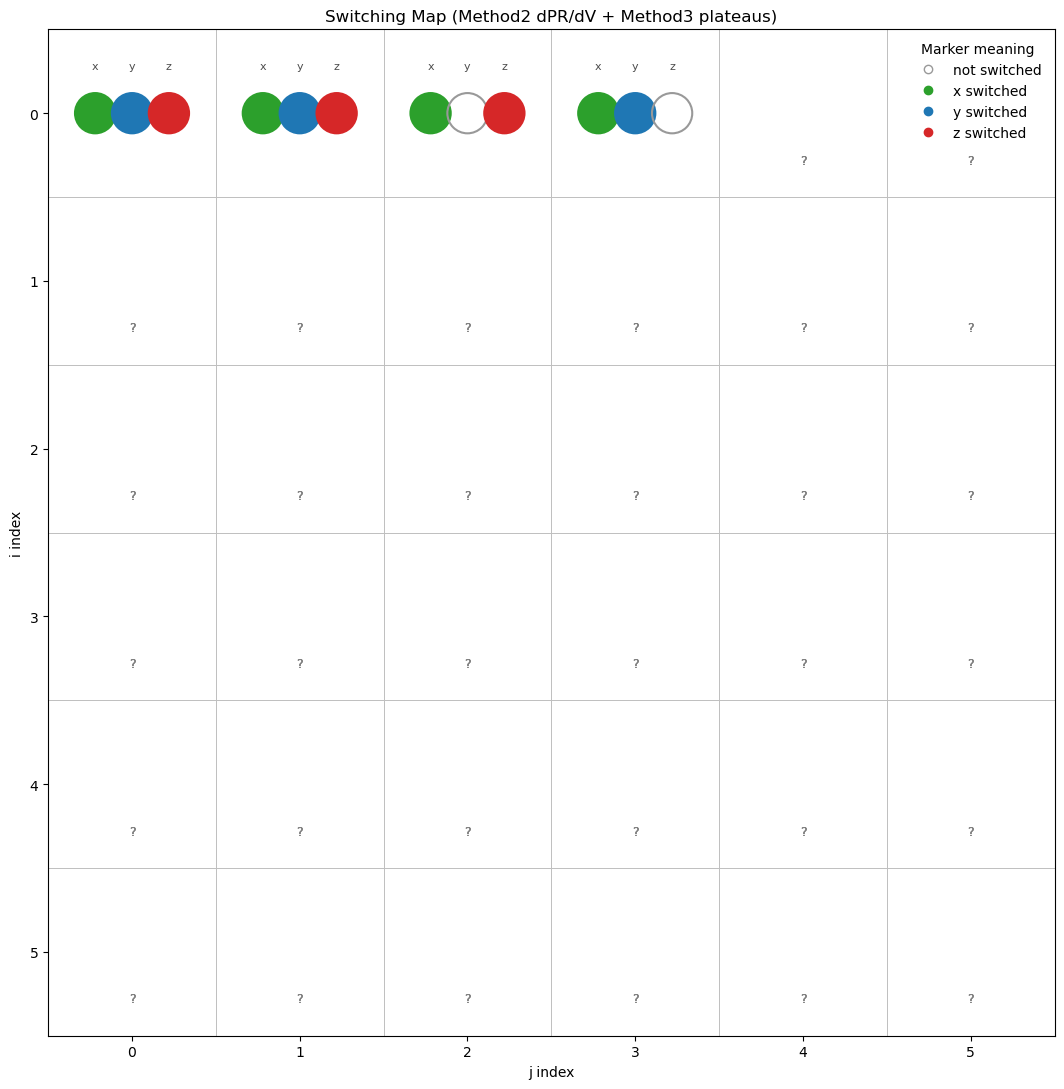

In [137]:
from matplotlib.patches import Rectangle, Circle

# -------------------- Tunable params --------------------
combine_mode = 'and'   # 'and' requires both methods agree; 'or' if either detects switching

# Method 2 (derivative on PR) thresholds
M2_min_sep_frac  = 0.15   # min bias separation (fraction of full span) between + and - derivative peaks
M2_min_prom_frac = 0.15   # min combined peak magnitude relative to PR span
M2_smooth_win    = 7      # odd window for simple smoothing before derivative

# Method 3 (plateau sign test) thresholds
M3_frac_plateau  = 0.2    # fraction of ends treated as plateaus (each side)
M3_min_mag_frac  = 0.2    # minimal combined |PR| on plateaus relative to PR span
M3_allow_offset  = True   # remove small mid-bias offset before testing sign

# Colors for x,y,z markers
comp_colors = {"x": "tab:green", "y": "tab:blue", "z": "tab:red"}

# -------------------- Helpers for methods --------------------
def _smooth_and_deriv(y, win=7):
    """Simple moving-average smoothing and numerical derivative (no scipy)."""
    y = np.asarray(y, float)
    win = win if (win % 2 == 1) else (win + 1)
    if win < 3 or win > y.size:
        return y.copy(), np.gradient(y)
    k = win // 2
    kernel = np.ones(2*k+1) / (2*k+1)
    ys = np.convolve(y, kernel, mode='same')
    dy = np.gradient(ys)
    return ys, dy

def detect_switch_dPR(bias, w_complex, min_sep_frac=0.15, min_prom_frac=0.15, smooth_win=7):
    """
    Method 2: Switch if dPR/dV has a major positive and negative peak,
    sufficiently separated in bias and with enough prominence.
    """
    bias = np.asarray(bias, float)
    if bias.size < 5 or not np.isfinite(bias).all():
        return False, {"reason": "bad_bias"}

    PR = np.real(w_complex)  # in-phase PR
    finite = np.isfinite(PR)
    if finite.sum() < 5:
        return False, {"reason": "insufficient_data"}

    PRs, dPR = _smooth_and_deriv(PR[finite], win=smooth_win)
    b  = bias[finite]

    pos_idx = int(np.argmax(dPR))
    neg_idx = int(np.argmin(dPR))
    pos_val = float(dPR[pos_idx])
    neg_val = float(dPR[neg_idx])

    # bias separation check
    bspan = float(np.nanmax(b) - np.nanmin(b)) if b.size > 1 else 0.0
    sep   = abs(b[pos_idx] - b[neg_idx]) if bspan > 0 else 0.0
    sep_ok = (bspan > 0) and (sep >= min_sep_frac * bspan)

    # "prominence" proxy vs PR span
    pr_span = float(np.nanmax(PRs) - np.nanmin(PRs)) if np.isfinite(PRs).all() else 0.0
    prom_ok = (abs(pos_val) + abs(neg_val)) >= (min_prom_frac * max(1e-12, pr_span))

    switched = (pos_val > 0) and (neg_val < 0) and sep_ok and prom_ok
    return switched, {
        "pos_idx": pos_idx, "neg_idx": neg_idx,
        "sep_bias": float(sep), "pos_val": pos_val, "neg_val": neg_val,
        "pr_span": pr_span, "sep_ok": bool(sep_ok), "prom_ok": bool(prom_ok)
    }

def detect_switch_plateau(bias, w_complex, frac_plateau=0.2, min_mag_frac=0.2, allow_offset=True):
    """
    Method 3: Compare high-|V| plateaus. Opposite signs with enough magnitude => switched.
    """
    bias = np.asarray(bias, float)
    if bias.size < 5 or not np.isfinite(bias).all():
        return False, {"reason": "bad_bias"}

    PR = np.real(w_complex).astype(float)
    finite = np.isfinite(PR)
    if finite.sum() < 5:
        return False, {"reason": "insufficient_data"}

    b = bias[finite]
    PR = PR[finite]

    if allow_offset:
        # remove small mid-bias offset using center 60% of span
        bmin, bmax = float(np.min(b)), float(np.max(b))
        span = bmax - bmin if bmax > bmin else 1.0
        mid_mask = np.abs(b - (bmin + 0.5*span)) <= 0.3*span
        if np.any(mid_mask):
            PR = PR - float(np.nanmedian(PR[mid_mask]))

    # select plateaus
    bmin, bmax = float(np.min(b)), float(np.max(b))
    span = bmax - bmin if bmax > bmin else 1.0
    hi_pos = b >= (bmin + (1-frac_plateau)*span)
    hi_neg = b <= (bmin + frac_plateau*span)

    if not np.any(hi_pos) or not np.any(hi_neg):
        return False, {"reason": "no_plateau"}

    m_pos = float(np.nanmedian(PR[hi_pos]))
    m_neg = float(np.nanmedian(PR[hi_neg]))

    pr_span = float(np.nanmax(PR) - np.nanmin(PR)) if np.isfinite(PR).all() else 0.0
    mag_ok  = (abs(m_pos) + abs(m_neg)) >= (min_mag_frac * max(1e-12, pr_span))
    sign_ok = (m_pos * m_neg) < 0.0

    switched = bool(sign_ok and mag_ok)
    return switched, {"PR_pos": m_pos, "PR_neg": m_neg, "pr_span": pr_span,
                      "sign_ok": bool(sign_ok), "mag_ok": bool(mag_ok)}

def classify_switch_combined(bias, w_complex,
                             combine='and',
                             m2_kwargs=None, m3_kwargs=None):
    """Run Method 2 and Method 3, then combine their decisions."""
    m2_kwargs = {} if m2_kwargs is None else dict(m2_kwargs)
    m3_kwargs = {} if m3_kwargs is None else dict(m3_kwargs)

    sw2, d2 = detect_switch_dPR(bias, w_complex, **m2_kwargs)
    sw3, d3 = detect_switch_plateau(bias, w_complex, **m3_kwargs)

    if combine == 'and':
        sw = bool(sw2 and sw3)
    elif combine == 'or':
        sw = bool(sw2 or sw3)
    else:
        raise ValueError("combine must be 'and' or 'or'")

    return sw, {"m2": d2, "m3": d3, "sw2": bool(sw2), "sw3": bool(sw3), "combine": combine}

# -------------------- Classify across the grid --------------------
nx, ny = len(grid_i), len(grid_j)
switched_x = [[None]*ny for _ in range(nx)]
switched_y = [[None]*ny for _ in range(nx)]
switched_z = [[None]*ny for _ in range(nx)]

for i_idx, i in enumerate(grid_i):
    for j_idx, j in enumerate(grid_j):
        folder_name = os.path.join(path_save, f"({i},{j})")
        filename_base = f"OFF_Loops_Map_({i},{j})"
        files = {
            "Left":   os.path.join(folder_name, f"{filename_base}_Left.txt"),
            "Right":  os.path.join(folder_name, f"{filename_base}_Right.txt"),
            "Past":   os.path.join(folder_name, f"{filename_base}_Past.txt"),
            "Before": os.path.join(folder_name, f"{filename_base}_Before.txt"),
        }
        if not all(os.path.exists(f) for f in files.values()):
            continue  # leave as None (missing)

        # Load
        bias_L, A_L, P_L = _load_xyphi(files["Left"])
        bias_R, A_R, P_R = _load_xyphi(files["Right"])
        bias_P, A_P, P_P = _load_xyphi(files["Past"])
        bias_B, A_B, P_B = _load_xyphi(files["Before"])

        # Phasors + rotation
        w_L = compute_phasor(A_L, P_L, assume_degrees=ASSUME_PHASE_DEGREES)
        w_R = compute_phasor(A_R, P_R, assume_degrees=ASSUME_PHASE_DEGREES)
        w_P = compute_phasor(A_P, P_P, assume_degrees=ASSUME_PHASE_DEGREES)
        w_B = compute_phasor(A_B, P_B, assume_degrees=ASSUME_PHASE_DEGREES)

        phi_inst = estimate_phi_inst([w_L, w_R, w_P, w_B])
        wL = rotate_phase(w_L, phi_inst)
        wR = rotate_phase(w_R, phi_inst)
        wP = rotate_phase(w_P, phi_inst)
        wB = rotate_phase(w_B, phi_inst)

        # Vector reconstruction
        if USE_WEIGHTED:
            ux_c, uy_c, uz_c = vector_components_weighted(
                wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR,
                L=L, x_plus=+dx, x_minus=-dx, y_plus=+dy, y_minus=-dy,
                h=h, r0=r0
            )
        else:
            ux_c, uy_c, uz_c = vector_components_simple(
                wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR
            )

        # Complex PR for each axis (compute_deff returns complex response)
        ux_map = compute_deff(ux_c, Vac=VAC, use_inphase=USE_INPHASE)
        uy_map = compute_deff(uy_c, Vac=VAC, use_inphase=USE_INPHASE)
        uz_map = compute_deff(uz_c, Vac=VAC, use_inphase=USE_INPHASE)

        # Use the same bias axis (assuming all equal length/order); otherwise choose per-component
        bias = bias_L

        # Combined classification for x,y,z
        kwargs_m2 = dict(min_sep_frac=M2_min_sep_frac, min_prom_frac=M2_min_prom_frac, smooth_win=M2_smooth_win)
        kwargs_m3 = dict(frac_plateau=M3_frac_plateau, min_mag_frac=M3_min_mag_frac, allow_offset=M3_allow_offset)

        swx, _ = classify_switch_combined(bias, ux_map, combine=combine_mode, m2_kwargs=kwargs_m2, m3_kwargs=kwargs_m3)
        swy, _ = classify_switch_combined(bias, uy_map, combine=combine_mode, m2_kwargs=kwargs_m2, m3_kwargs=kwargs_m3)
        swz, _ = classify_switch_combined(bias, uz_map, combine=combine_mode, m2_kwargs=kwargs_m2, m3_kwargs=kwargs_m3)

        switched_x[i_idx][j_idx] = swx
        switched_y[i_idx][j_idx] = swy
        switched_z[i_idx][j_idx] = swz

# -------------------- Plot the 3-marker switching grid --------------------
fig, ax = plt.subplots(figsize=(1.5*len(grid_j)+2, 1.5*len(grid_i)+2))
ax.set_aspect('equal')
ax.set_xlim(-0.5, len(grid_j)-0.5)
ax.set_ylim(-0.5, len(grid_i)-0.5)
ax.invert_yaxis()

# Grid boxes
for i_idx in range(len(grid_i)):
    for j_idx in range(len(grid_j)):
        ax.add_patch(Rectangle((j_idx-0.5, i_idx-0.5), 1.0, 1.0, fill=False, lw=0.6, ec='0.75'))

# Marker positions within each cell
offsets = {'x': (-0.22, 0.0), 'y': (0.00, 0.0), 'z': (0.22, 0.0)}
radius = 0.12

def draw_marker(i_idx, j_idx, comp_key, state):
    cx = j_idx + offsets[comp_key][0]
    cy = i_idx + offsets[comp_key][1]
    color = comp_colors[comp_key]
    if state is None:
        ax.text(j_idx, i_idx+0.28, "?", ha='center', va='center', fontsize=9, color='0.5')
        return
    face = color if state else 'none'
    edge = color if state else '0.6'
    ax.add_patch(Circle((cx, cy), radius=radius, facecolor=face, edgecolor=edge, lw=1.5))
    if i_idx == 0:
        ax.text(cx, cy-0.28, comp_key, ha='center', va='center', fontsize=8, color='0.3')

for i_idx in range(len(grid_i)):
    for j_idx in range(len(grid_j)):
        draw_marker(i_idx, j_idx, 'x', switched_x[i_idx][j_idx])
        draw_marker(i_idx, j_idx, 'y', switched_y[i_idx][j_idx])
        draw_marker(i_idx, j_idx, 'z', switched_z[i_idx][j_idx])

ax.set_xticks(range(len(grid_j))); ax.set_yticks(range(len(grid_i)))
ax.set_xticklabels([str(j) for j in grid_j]); ax.set_yticklabels([str(i) for i in grid_i])
ax.set_xlabel("j index"); ax.set_ylabel("i index")
ax.set_title(f"Switching Map (Method2 dPR/dV {'+' if combine_mode=='and' else 'or'} Method3 plateaus)")

# Legend
from matplotlib.lines import Line2D
legend_elems = [
    Line2D([0],[0], marker='o', linestyle='None', markerfacecolor='none', markeredgecolor='0.6', label='not switched'),
    Line2D([0],[0], marker='o', linestyle='None', markerfacecolor='tab:green', markeredgecolor='tab:green', label='x switched'),
    Line2D([0],[0], marker='o', linestyle='None', markerfacecolor='tab:blue',  markeredgecolor='tab:blue',  label='y switched'),
    Line2D([0],[0], marker='o', linestyle='None', markerfacecolor='tab:red',   markeredgecolor='tab:red',   label='z switched'),
]
ax.legend(handles=legend_elems, loc='upper right', frameon=False, title="Marker meaning")

plt.tight_layout()
plt.show()

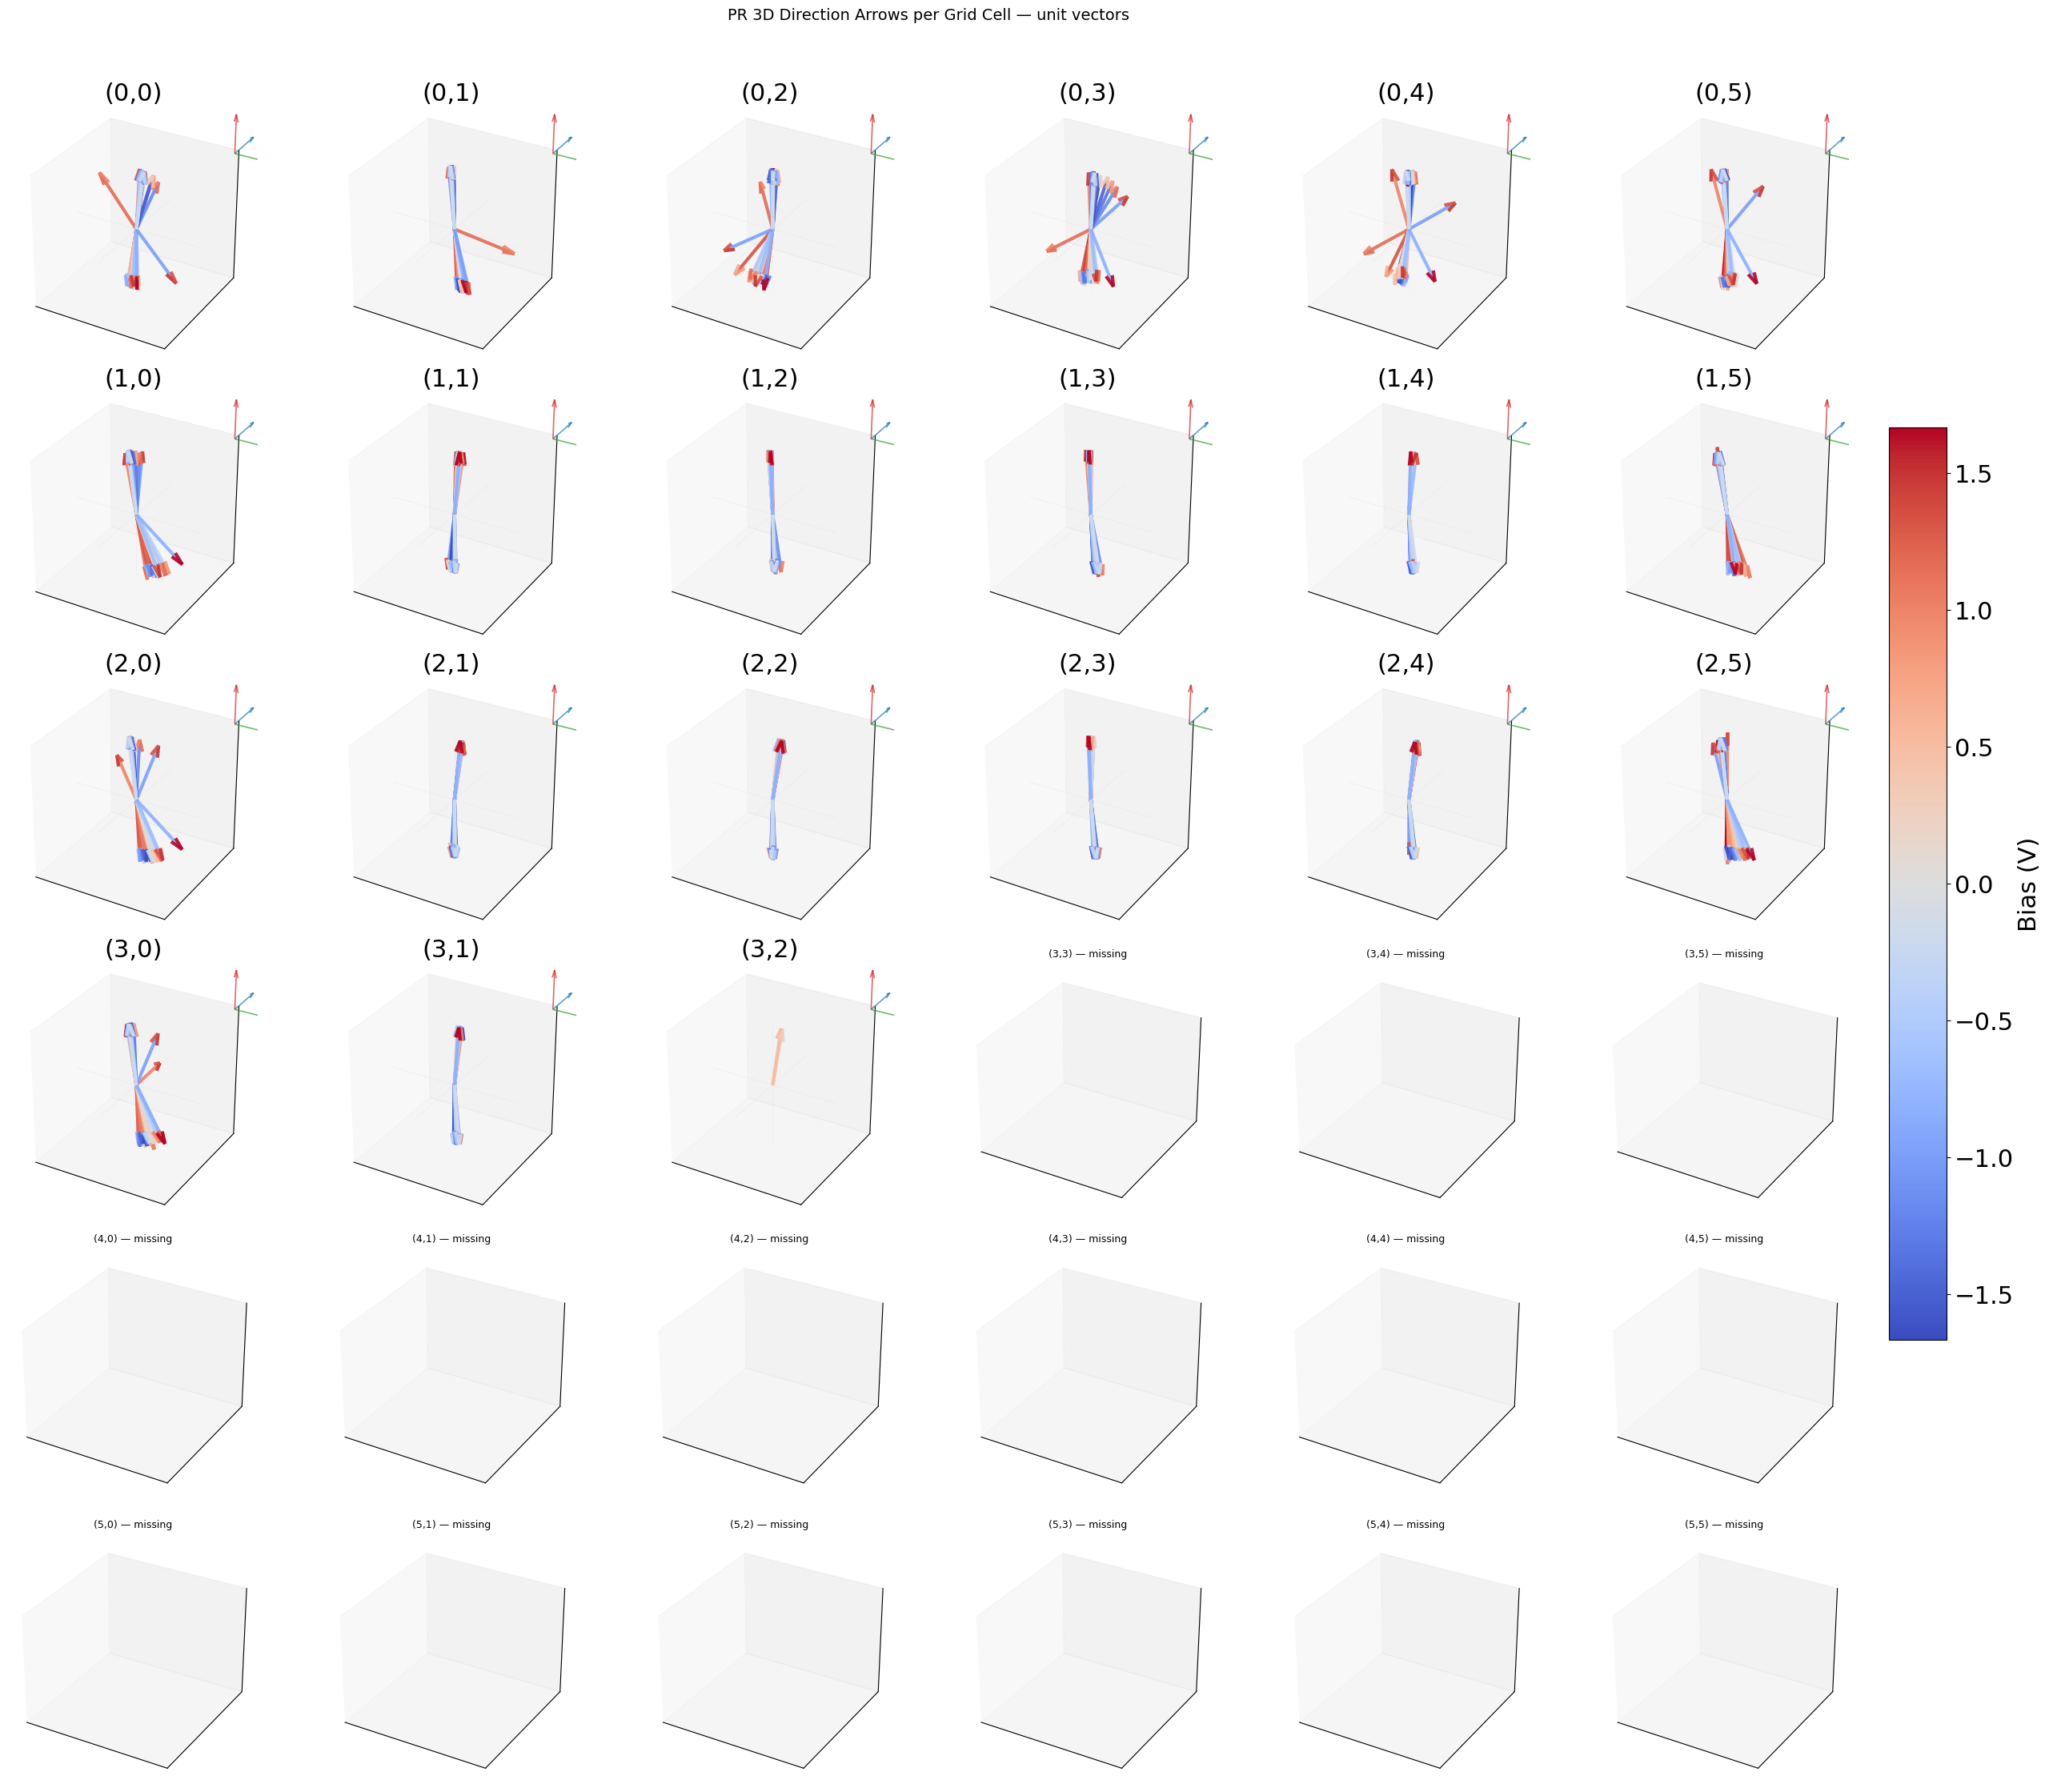

In [147]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (import activates 3D projection)
from matplotlib import cm, colors

# ---------- Tuning knobs ----------
factor_in_out     = 1.0     # visualization scaling for in-plane (ux, uy)
vector_mode       = 'unit'  # 'unit' for direction-only; 'scaled' for true magnitude arrows
arrow_scale       = 1.0     # multiplies arrow length when vector_mode='scaled'
downsample_every  = 1       # e.g., 2 to plot every 2nd bias point
arrow_alpha       = 0.9     # arrow opacity
arrow_linewidth   = 3
equal_axes_margin = 1.05    # expand axis limits by this factor

# Color map for bias
#cmap = cm.viridis
cmap = cm.coolwarm

# ---------- Helper to compute PR vectors for one grid cell ----------
def reconstruct_PR_vectors_for_cell(i, j):
    """Return bias array and PRx, PRy, PRz arrays (same length) for grid cell (i,j).
       Returns (None, None, None, None) if files missing or invalid.
    """
    folder_name = os.path.join(path_save, f"({i},{j})")
    filename_base = f"OFF_Loops_Map_({i},{j})"
    files = {
        "Left":   os.path.join(folder_name, f"{filename_base}_Left.txt"),
        "Right":  os.path.join(folder_name, f"{filename_base}_Right.txt"),
        "Past":   os.path.join(folder_name, f"{filename_base}_Past.txt"),
        "Before": os.path.join(folder_name, f"{filename_base}_Before.txt"),
    }
    if not all(os.path.exists(f) for f in files.values()):
        return None, None, None, None

    # Load loops
    bias_L, A_L, P_L = _load_xyphi(files["Left"])
    bias_R, A_R, P_R = _load_xyphi(files["Right"])
    bias_P, A_P, P_P = _load_xyphi(files["Past"])
    bias_B, A_B, P_B = _load_xyphi(files["Before"])

    # Build phasors and rotate to instantaneous phase reference
    w_L = compute_phasor(A_L, P_L, assume_degrees=ASSUME_PHASE_DEGREES)
    w_R = compute_phasor(A_R, P_R, assume_degrees=ASSUME_PHASE_DEGREES)
    w_P = compute_phasor(A_P, P_P, assume_degrees=ASSUME_PHASE_DEGREES)
    w_B = compute_phasor(A_B, P_B, assume_degrees=ASSUME_PHASE_DEGREES)

    phi_inst = estimate_phi_inst([w_L, w_R, w_P, w_B])
    wL = rotate_phase(w_L, phi_inst)
    wR = rotate_phase(w_R, phi_inst)
    wP = rotate_phase(w_P, phi_inst)
    wB = rotate_phase(w_B, phi_inst)

    # Vector reconstruction (complex)
    if USE_WEIGHTED:
        ux_c, uy_c, uz_c = vector_components_weighted(
            wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR,
            L=L, x_plus=+dx, x_minus=-dx, y_plus=+dy, y_minus=-dy,
            h=h, r0=r0
        )
    else:
        ux_c, uy_c, uz_c = vector_components_simple(
            wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR
        )

    # Complex effective response per axis
    ux = compute_deff(ux_c, Vac=VAC, use_inphase=USE_INPHASE)
    uy = compute_deff(uy_c, Vac=VAC, use_inphase=USE_INPHASE)
    uz = compute_deff(uz_c, Vac=VAC, use_inphase=USE_INPHASE)

    # Visualization scaling for in-plane
    ux = ux * factor_in_out
    uy = uy * factor_in_out

    # Piezoresponse component for each axis: PR = A*cos(phi) = Re(complex)
    PRx = np.real(ux)
    PRy = np.real(uy)
    PRz = np.real(uz)

    # Use Left bias as the x-axis for plotting (adjust if yours differ)
    bias = np.asarray(bias_L)

    # Downsample if requested
    if downsample_every > 1 and bias.size >= downsample_every:
        sel = slice(None, None, downsample_every)
        return bias[sel], PRx[sel], PRy[sel], PRz[sel]
    else:
        return bias, PRx, PRy, PRz

# ---------- Collect global limits (for uniform axis scaling) ----------
all_mags = []
all_bias_vals = []

for i in grid_i:
    for j in grid_j:
        bias, PRx, PRy, PRz = reconstruct_PR_vectors_for_cell(i, j)
        if bias is None:
            continue
        if vector_mode == 'unit':
            mags = np.ones_like(bias, dtype=float)
        else:
            mags = np.sqrt(PRx**2 + PRy**2 + PRz**2)
        all_mags.append(mags)
        all_bias_vals.append(bias)

if len(all_mags) == 0:
    raise RuntimeError("No valid cells found for PR vector plotting.")

max_mag = np.nanmax(np.concatenate(all_mags)) if vector_mode == 'scaled' else 1.0
bias_min = np.nanmin(np.concatenate(all_bias_vals))
bias_max = np.nanmax(np.concatenate(all_bias_vals))
bias_span = max(bias_max - bias_min, 1e-12)

# Axis range (symmetric) for each 3D subplot
lim = equal_axes_margin * (arrow_scale * max_mag if vector_mode == 'scaled' else 1.0)

# Color normalization for bias
norm = colors.Normalize(vmin=bias_min, vmax=bias_max)
sm = cm.ScalarMappable(norm=norm, cmap=cmap)

# ---------- Build the grid of 3D subplots ----------
nrows, ncols = len(grid_i), len(grid_j)
fig = plt.figure(figsize=(4*ncols, 3.8*nrows))

# We will use a simple row-major indexing consistent with your (i_idx, j_idx)
subplot_idx = 1

for i_idx, i in enumerate(grid_i):
    for j_idx, j in enumerate(grid_j):
        ax = fig.add_subplot(nrows, ncols, subplot_idx, projection='3d')
        subplot_idx += 1

        bias, PRx, PRy, PRz = reconstruct_PR_vectors_for_cell(i, j)
        if bias is None:
            ax.set_title(f"({i},{j}) — missing", fontsize=9)
            ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
            ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
            continue

        # Prepare arrows from origin: one per bias
        X0 = np.zeros_like(bias); Y0 = np.zeros_like(bias); Z0 = np.zeros_like(bias)
        U  = PRx.copy(); V = PRy.copy(); W = PRz.copy()

        if vector_mode == 'unit':
            mag = np.sqrt(U**2 + V**2 + W**2)
            # avoid divide-by-zero
            good = mag > 0
            U[good] /= mag[good]
            V[good] /= mag[good]
            W[good] /= mag[good]
            # length parameter scales the arrows visually for unit vectors
            length_param = arrow_scale
            normalize_flag = False  # already normalized
        else:
            # keep magnitudes, but allow a global scale
            U *= arrow_scale
            V *= arrow_scale
            W *= arrow_scale
            length_param = 1.0
            normalize_flag = False

        # Colors by bias
        cols = cmap(norm(bias))

        # Plot quiver (one arrow per bias sample)
        ax.quiver(X0, Y0, Z0, U, V, W,
                  length=length_param,
                  normalize=normalize_flag,
                  arrow_length_ratio=0.2,
                  colors=cols,
                  linewidths=arrow_linewidth,
                  alpha=arrow_alpha)

        # Cosmetic: equal-ish axes & light guides
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
        ax.set_box_aspect((1, 1, 1))
        ax.set_title(f"({i},{j})", fontsize=22)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

        # small axis triad at origin
        triad_len = 0.6 * lim
        ax.quiver(lim,lim,lim, triad_len,0,0, color='tab:green', arrow_length_ratio=0.2, linewidths=1.2, alpha=0.7)
        ax.quiver(lim,lim,lim, 0,triad_len,0, color='tab:blue',  arrow_length_ratio=0.2, linewidths=1.2, alpha=0.7)
        ax.quiver(lim,lim,lim, 0,0,triad_len, color='tab:red',   arrow_length_ratio=0.2, linewidths=1.2, alpha=0.7)

        # center crosshair (optional)
        ax.plot([ -lim,  lim], [0,0], [0,0], color='0.9', lw=0.5, alpha=0.6)
        ax.plot([0,0], [ -lim,  lim], [0,0], color='0.9', lw=0.5, alpha=0.6)
        ax.plot([0,0], [0,0], [ -lim,  lim], color='0.9', lw=0.5, alpha=0.6)

# ----- Colorbar for bias (moved to right side) -----
# ----- Colorbar for bias (moved fully to the right side) -----
from mpl_toolkits.axes_grid1 import make_axes_locatable

# STEP 1: give the subplots a bit less horizontal space
fig.subplots_adjust(right=0.85)  # smaller = more space on the right

# STEP 2: manually position the colorbar axis
# Parameters are [left, bottom, width, height] in *figure coordinates*
cbar_left = 1   # push this higher (e.g., 0.89 → 0.92) to move it further right
cbar_bottom = 0.25 # lower edge; increase to move upward
cbar_width = 0.03  # thickness; increase to make it wider
cbar_height = 0.5 # total vertical span (0–1 = full figure)
cbar_ax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

# STEP 3: draw the colorbar in that axis
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("Bias (V)", fontsize='22')
cbar.ax.tick_params(labelsize=22)   

mode_note = "unit vectors" if vector_mode=='unit' else "scaled by |PR|"
scale_note = "" if factor_in_out == 1.0 else f" (in-plane ×{factor_in_out:g})"
fig.suptitle(f"PR 3D Direction Arrows per Grid Cell — {mode_note}{scale_note}", fontsize=14)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

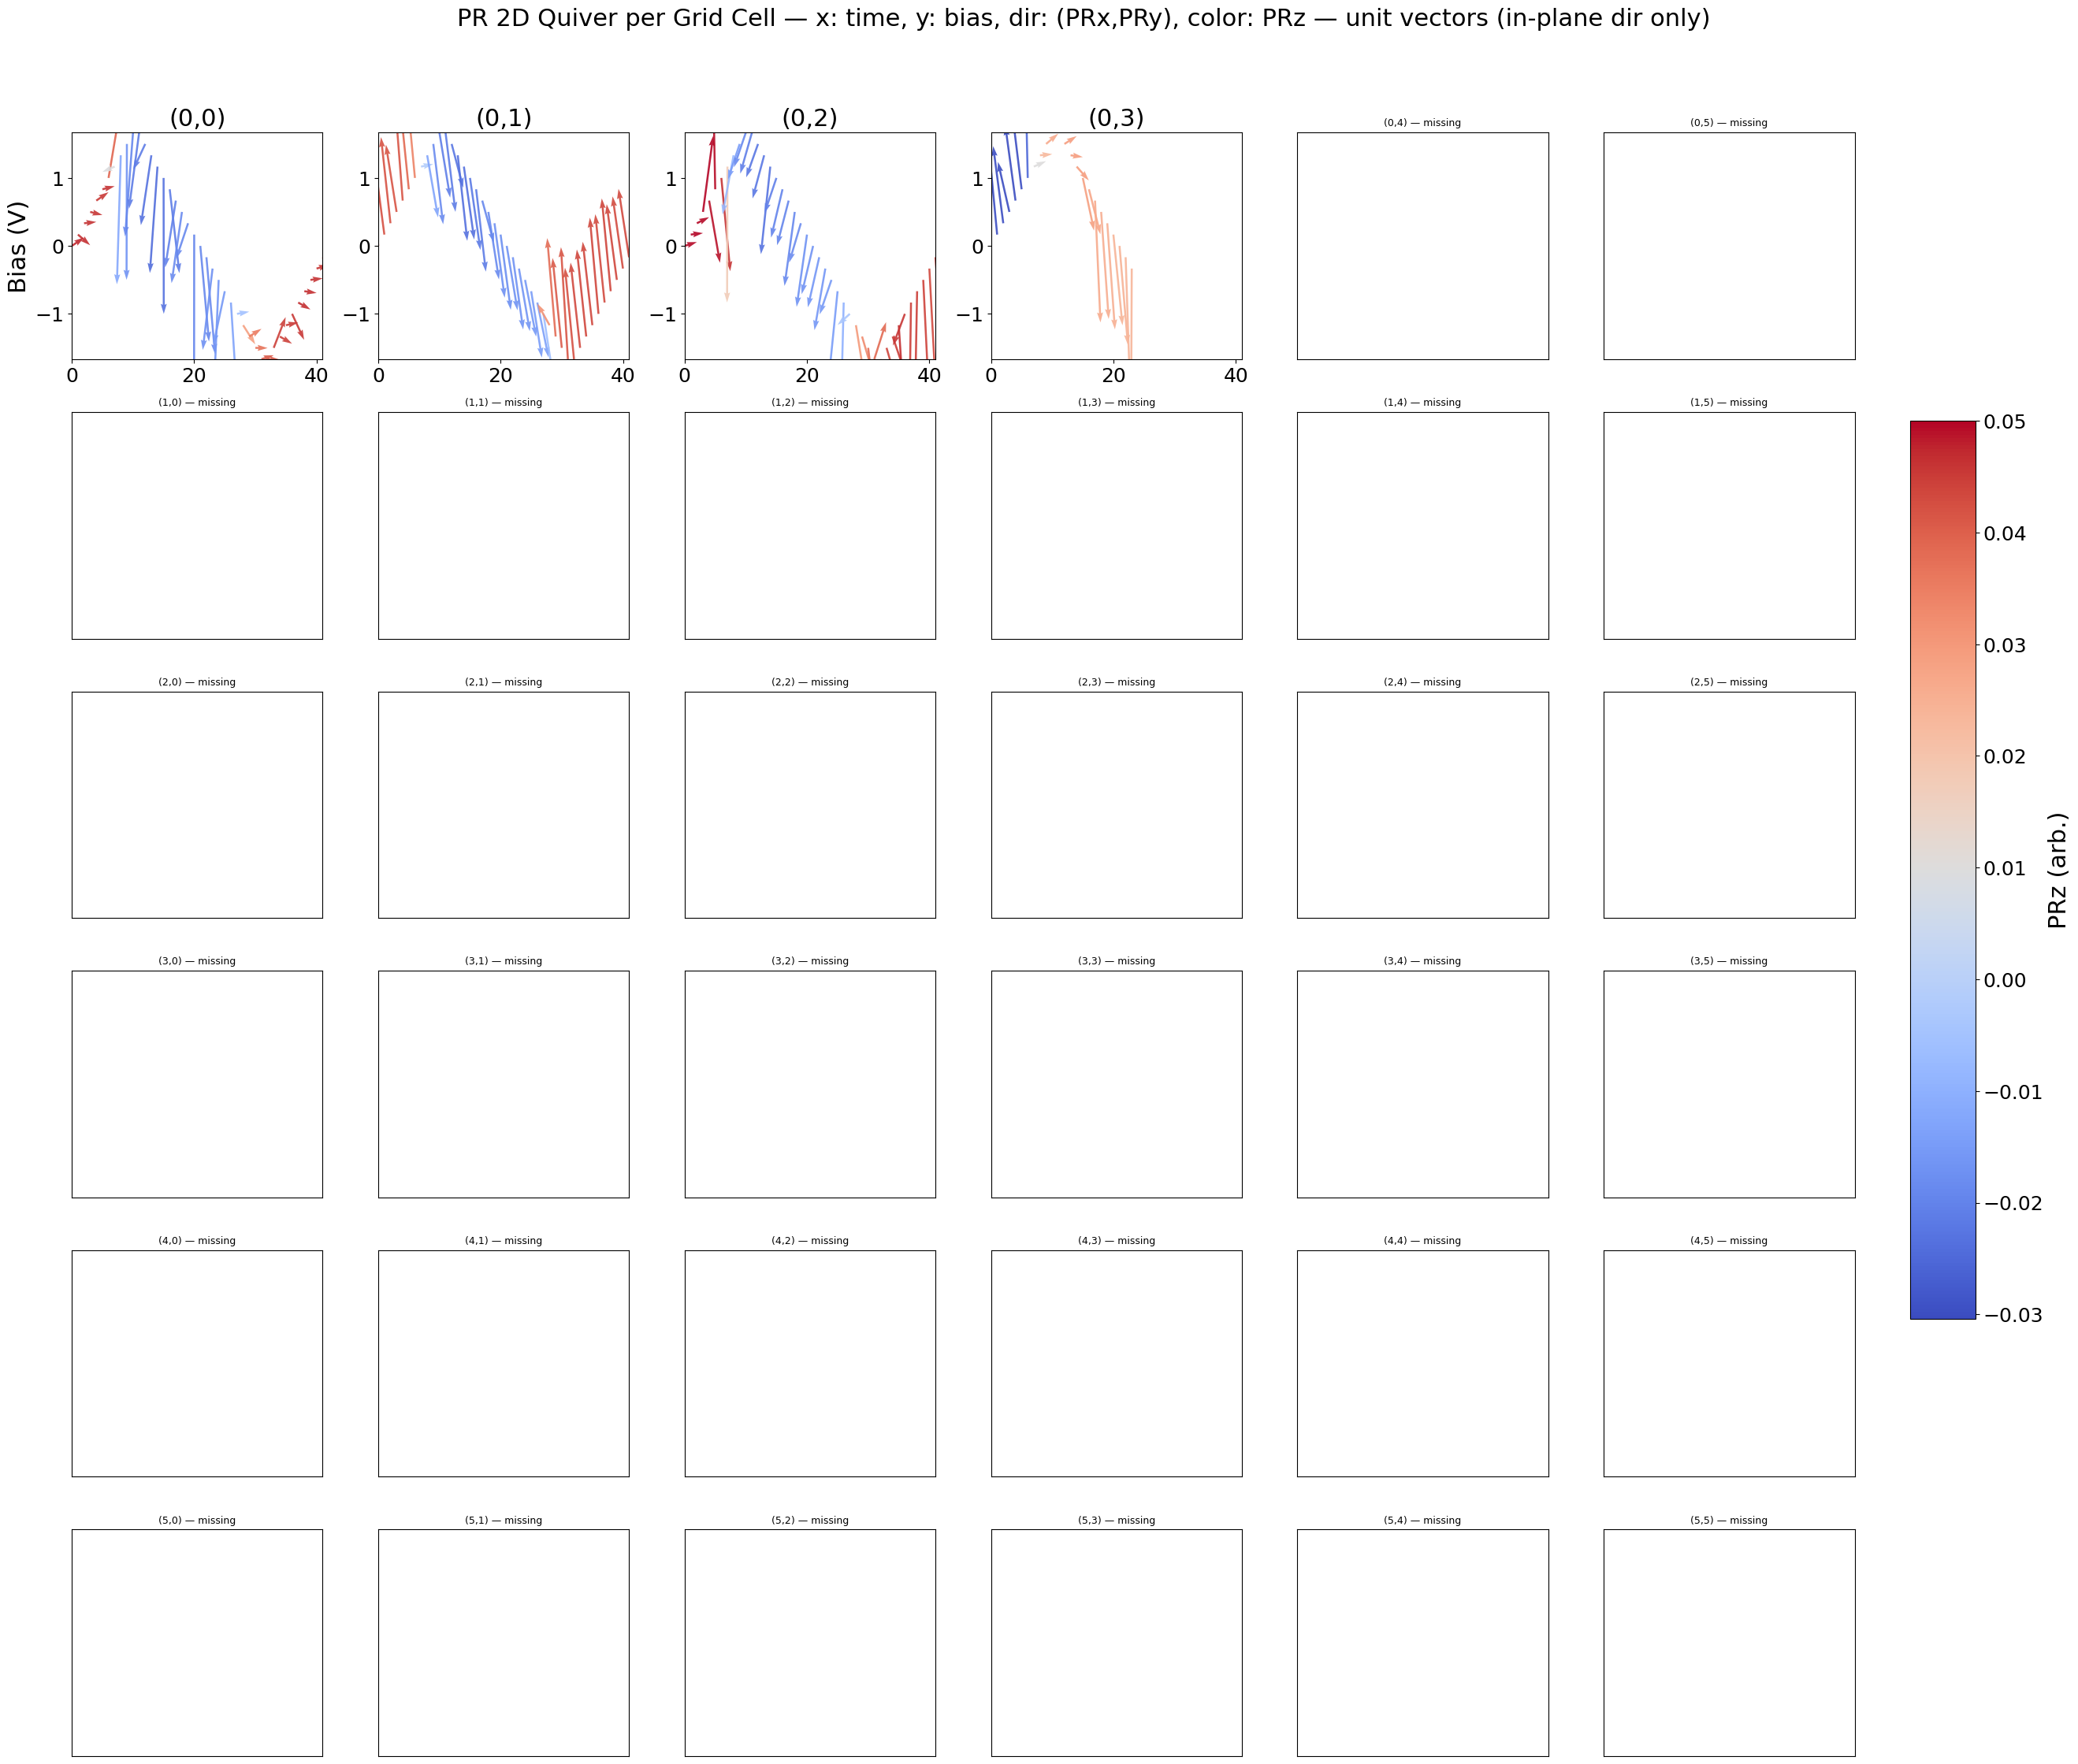

In [139]:
# ---- Tuning knobs (2D variant) ----
vector_mode_2d  = 'unit'   # 'unit' for direction-only; 'scaled' to scale by in-plane magnitude
arrow_len_data  = 2     # arrow length in *data coords* (applies when vector_mode_2d='unit')
arrow_scale_2d  = 2.0      # global multiplier when vector_mode_2d='scaled' (fraction of max in-plane)
arrow_alpha_2d  = 0.9
arrow_linewidth_2d = 3
arrow_width_2d  = 0.008    # thickness of arrow shafts (data->axes scaled)
title_fs        = 22
tick_fs         = 18
label_fs        = 22

cmap2d = cm.coolwarm  # PRz color map

# ---- Gather global ranges (bias, PRz, time length) ----
all_bias_vals = []
all_prz_vals  = []
max_len = 0

for i in grid_i:
    for j in grid_j:
        bias, PRx, PRy, PRz = reconstruct_PR_vectors_for_cell(i, j)
        if bias is None:
            continue
        all_bias_vals.append(bias)
        all_prz_vals.append(PRz)
        max_len = max(max_len, len(bias))

if len(all_bias_vals) == 0:
    raise RuntimeError("No valid cells found for 2D quiver plotting.")

bias_min = float(np.nanmin(np.concatenate(all_bias_vals)))
bias_max = float(np.nanmax(np.concatenate(all_bias_vals)))
prz_min  = float(np.nanmin(np.concatenate(all_prz_vals)))
prz_max  = float(np.nanmax(np.concatenate(all_prz_vals)))

# Normalizer / sm for PRz colorbar
norm_prz = colors.Normalize(vmin=prz_min, vmax=prz_max)
sm_prz   = cm.ScalarMappable(norm=norm_prz, cmap=cmap2d)

# Optional: global max in-plane magnitude for 'scaled' mode
if vector_mode_2d == 'scaled':
    all_inplane = []
    for i in grid_i:
        for j in grid_j:
            bias, PRx, PRy, PRz = reconstruct_PR_vectors_for_cell(i, j)
            if bias is None:
                continue
            all_inplane.append(np.sqrt(PRx**2 + PRy**2))
    max_inplane = float(np.nanmax(np.concatenate(all_inplane)))
    if not np.isfinite(max_inplane) or max_inplane == 0:
        max_inplane = 1.0  # avoid divide-by-zero

# ---- Build subplot grid ----
nrows, ncols = len(grid_i), len(grid_j)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6*ncols, 3.8*nrows), squeeze=False)

for i_idx, i in enumerate(grid_i):
    for j_idx, j in enumerate(grid_j):
        ax = axes[i_idx, j_idx]

        bias, PRx, PRy, PRz = reconstruct_PR_vectors_for_cell(i, j)
        if bias is None:
            ax.set_title(f"({i},{j}) — missing", fontsize=9)
            ax.set_xlim(0, max_len-1)
            ax.set_ylim(bias_min, bias_max)
            ax.set_xticks([]); ax.set_yticks([])
            continue

        # Time index (x) and bias (y) locations for arrows
        t = np.arange(len(bias))
        x_pos = t
        y_pos = bias

        # In-plane components for arrow direction
        U = np.array(PRx, dtype=float).copy()
        V = np.array(PRy, dtype=float).copy()

        # Color by PRz
        C = cmap2d(norm_prz(PRz))

        # Scale/normalize the in-plane vectors
        if vector_mode_2d == 'unit':
            mag = np.sqrt(U**2 + V**2)
            good = mag > 0
            U[good] = (U[good] / mag[good]) * arrow_len_data
            V[good] = (V[good] / mag[good]) * arrow_len_data
            # zero-length where mag==0
            U[~good] = 0.0
            V[~good] = 0.0
            scale_units = 'xy'
            scale_val   = 1
        else:
            # scaled by global in-plane magnitude (so largest arrow ~ arrow_scale_2d in *x-data units*)
            inplane = np.sqrt(U**2 + V**2)
            with np.errstate(invalid='ignore', divide='ignore'):
                U = U / max_inplane
                V = V / max_inplane
            U = np.nan_to_num(U) * arrow_scale_2d
            V = np.nan_to_num(V) * arrow_scale_2d
            scale_units = 'xy'
            scale_val   = 1

        # Plot arrows (pivot at tail so they "grow" from the sample point)
        q = ax.quiver(
            x_pos, y_pos, U, V,
            color=C,
            angles='xy', scale_units=scale_units, scale=scale_val,
            width=arrow_width_2d,
            linewidths=arrow_linewidth_2d,
            alpha=arrow_alpha_2d,
            pivot='tail'
        )

        # Cosmetics
        ax.set_xlim(0, max_len-1)
        ax.set_ylim(bias_min, bias_max)
        ax.set_title(f"({i},{j})", fontsize=title_fs)
        if i_idx == nrows - 1:
            ax.set_xlabel("Time index", fontsize=label_fs)
        if j_idx == 0:
            ax.set_ylabel("Bias (V)", fontsize=label_fs)
        ax.tick_params(labelsize=tick_fs)

# ---- Colorbar for PRz on the right, non-overlapping ----
fig.subplots_adjust(right=0.85)  # free up space on the right
cbar_ax = fig.add_axes([0.88, 0.25, 0.03, 0.5])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(sm_prz, cax=cbar_ax)
cbar.set_label("PRz (arb.)", fontsize=label_fs)
cbar.ax.tick_params(labelsize=tick_fs)

mode_note = "unit vectors (in-plane dir only)" if vector_mode_2d == 'unit' else "scaled by |PR_in-plane|"
fig.suptitle(f"PR 2D Quiver per Grid Cell — x: time, y: bias, dir: (PRx,PRy), color: PRz — {mode_note}", fontsize=title_fs)
plt.tight_layout(rect=[0, 0, 0.86, 0.95])
plt.show()